# Praktikum Data Mining
## Association Rule Mining (Market Basket Analysis)

### Dataset yang digunakan

1. `transactions_arm_praktikum.csv` — data transaksi dalam bentuk daftar item.
2. `transactions_arm_praktikum_onehot.csv` — data transaksi yang sudah berbentuk matriks One-Hot.

**Alur pengerjaan:**

1. Persiapan data transaksi.
2. Encoding ke format One-Hot.
3. Mencari frequent itemset dengan Apriori.
4. Membentuk aturan asosiasi.
5. Membuat visualisasi hasil.
6. Menginterpretasikan aturan asosiasi.
7. Menguji beberapa nilai `min_support`.
8. Membandingkan Apriori dan FP-Growth.

## 0. Persiapan lingkungan

### Import library

Library yang digunakan:

| Library | Kegunaan |
|---|---|
| `pandas` | Membaca dan mengolah data CSV |
| `numpy` | Membantu pengolahan data numerik |
| `Counter` | Menghitung frekuensi item |
| `TransactionEncoder` | Mengubah daftar transaksi menjadi One-Hot |
| `apriori` | Mencari frequent itemset dengan Apriori |
| `fpgrowth` | Mencari frequent itemset dengan FP-Growth |
| `association_rules` | Membentuk aturan asosiasi |
| `matplotlib` | Membuat grafik |
| `time` | Mengukur waktu eksekusi algoritma |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

from collections import Counter
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import (
    apriori,
    fpgrowth,
    association_rules
)

# Menampilkan versi pandas dan mlxtend (opsional)
import mlxtend
print("Versi pandas :", pd.__version__)
print("Versi mlxtend:", mlxtend.__version__)

Versi pandas : 2.3.3
Versi mlxtend: 0.25.0


---

# 4.1 Persiapan Data Transaksi

### Tujuan
Membaca data transaksi dari file CSV dan mengubah kolom `Items` menjadi **list of list**. Format ini diperlukan oleh `TransactionEncoder`.

Contoh satu transaksi:

```python
['Gula', 'Kopi', 'Susu']
```

### Membaca file CSV

Pastikan nama file dan lokasi file sesuai. Jika file berada di folder lain, tuliskan alamat/path file yang benar.

In [2]:
# Membaca dataset transaksi biasa
data = pd.read_csv("Data set/transactions_arm_praktikum.csv")

# Melihat beberapa baris awal untuk memeriksa struktur dataset
display(data.head())

# Memeriksa nama kolom
print("Nama kolom:", data.columns.tolist())
print("Jumlah baris:", len(data))

,TID,Items
0,T1,"Gula, Kopi, Susu"
1,T2,"Gula, Kopi, Susu"
2,T3,"Mentega, Roti, Susu, Telur"
3,T4,Mie Instan
4,T5,"Keju, Roti, Susu, Telur"


Nama kolom: ['TID', 'Items']
Jumlah baris: 60


### Mengubah kolom Items menjadi list of list

Kode berikut memisahkan nama item berdasarkan tanda koma. `strip()` menghapus spasi berlebih di awal atau akhir nama item.

In [3]:
# Memastikan kolom yang diperlukan tersedia
if not {"TID", "Items"}.issubset(data.columns):
    raise ValueError("Dataset harus memiliki kolom 'TID' dan 'Items'.")

# Mengubah setiap isi kolom Items menjadi daftar item
transactions = (
    data["Items"]
    .fillna("")
    .apply(lambda x: [item.strip() for item in str(x).split(",") if item.strip()])
    .tolist()
)

# Memastikan tidak ada transaksi kosong
if any(len(transaksi) == 0 for transaksi in transactions):
    raise ValueError("Terdapat transaksi kosong. Periksa file CSV.")

print("Jumlah transaksi:", len(transactions))

# Menampilkan lima transaksi pertama
for i, transaksi in enumerate(transactions[:5], start=1):
    print(f"T{i}: {transaksi}")

Jumlah transaksi: 60
T1: ['Gula', 'Kopi', 'Susu']
T2: ['Gula', 'Kopi', 'Susu']
T3: ['Mentega', 'Roti', 'Susu', 'Telur']
T4: ['Mie Instan']
T5: ['Keju', 'Roti', 'Susu', 'Telur']


### Menghitung frekuensi kemunculan setiap item

Frekuensi menunjukkan berapa kali sebuah item muncul di seluruh transaksi. Support item tunggal dihitung dengan rumus:

\[
Support(item) = \frac{Frekuensi\ item}{Jumlah\ transaksi}
\]

In [4]:
# Menghitung frekuensi setiap item
cnt = Counter()

for transaksi in transactions:
    cnt.update(transaksi)

# Menampilkan item dari frekuensi tertinggi
print("Frekuensi kemunculan item:")
for item, frekuensi in cnt.most_common():
    support = frekuensi / len(transactions)
    print(f"{item:12s}: {frekuensi:2d} (support = {support:.3f})")

Frekuensi kemunculan item:
Susu        : 19 (support = 0.317)
Roti        : 18 (support = 0.300)
Mie Instan  : 18 (support = 0.300)
Mentega     : 17 (support = 0.283)
Telur       : 15 (support = 0.250)
Sabun       : 15 (support = 0.250)
Gula        : 14 (support = 0.233)
Kopi        : 13 (support = 0.217)
Shampo      : 13 (support = 0.217)
Kecap       : 12 (support = 0.200)
Keju        :  6 (support = 0.100)
Teh         :  4 (support = 0.067)


### Visualisasi frekuensi item

Grafik batang membantu melihat item yang paling sering dan paling jarang muncul.

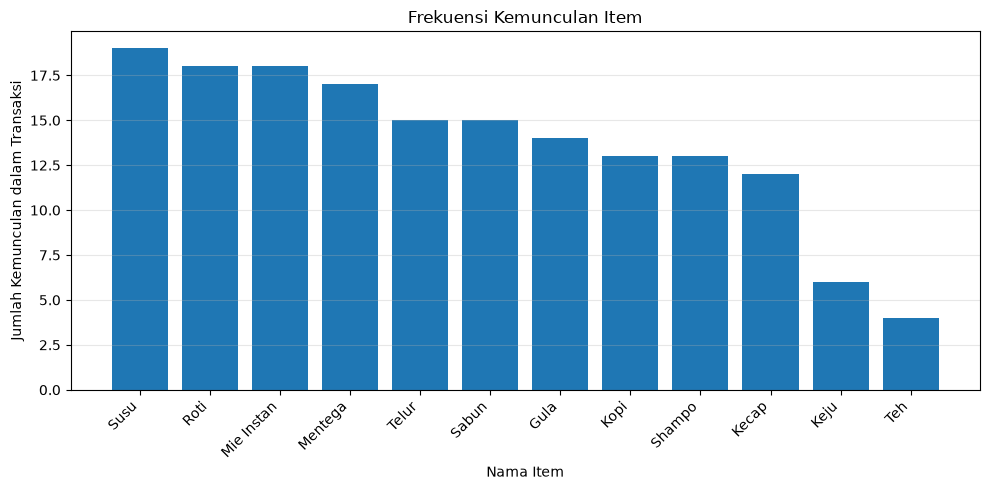

In [5]:
items = [item for item, frekuensi in cnt.most_common()]
frekuensi_items = [frekuensi for item, frekuensi in cnt.most_common()]

plt.figure(figsize=(10, 5))
plt.bar(items, frekuensi_items)
plt.title("Frekuensi Kemunculan Item")
plt.xlabel("Nama Item")
plt.ylabel("Jumlah Kemunculan dalam Transaksi")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Cara membaca hasil 4.1:** item dengan batang paling tinggi merupakan item yang paling sering muncul. Perhatikan apakah jumlah transaksi dan nama item sesuai dengan dataset yang diberikan dosen.

---

# 4.2 Encoding Data Transaksi ke Format One-Hot

### Tujuan
Mengubah `list of list` menjadi tabel dengan satu kolom untuk setiap item.

- `True`: item dibeli pada transaksi tersebut.
- `False`: item tidak dibeli pada transaksi tersebut.

Algoritma Apriori dan FP-Growth pada `mlxtend` menggunakan bentuk data seperti ini.

In [6]:
# Membuat objek TransactionEncoder
te = TransactionEncoder()

# Mempelajari item dan mengubah transaksi menjadi matriks True/False
te_ary = te.fit(transactions).transform(transactions)

# Membuat DataFrame One-Hot
df = pd.DataFrame(te_ary, columns=te.columns_)

print("Ukuran matriks One-Hot:", df.shape)
display(df.head())

Ukuran matriks One-Hot: (60, 12)


,Gula,Kecap,Keju,Kopi,Mentega,Mie Instan,Roti,Sabun,Shampo,Susu,Teh,Telur
0,True,False,False,True,False,False,False,False,False,True,False,False
1,True,False,False,True,False,False,False,False,False,True,False,False
2,False,False,False,False,True,False,True,False,False,True,False,True
3,False,False,False,False,False,True,False,False,False,False,False,False
4,False,False,True,False,False,False,True,False,False,True,False,True


### Memeriksa dataset One-Hot

File `transactions_arm_praktikum_onehot.csv` merupakan data One-Hot yang sudah disiapkan. Kita bandingkan dengan hasil encoding pada sel sebelumnya.

Pemeriksaan ini membantu memastikan kedua dataset mewakili transaksi yang sama. Kolom disusun ulang mengikuti urutan kolom hasil encoding sebelum dibandingkan.

In [7]:
# Membaca dataset One-Hot dari dosen
df_onehot_dosen = pd.read_csv("Data set/transactions_arm_praktikum_onehot.csv")

# Menyamakan urutan kolom dengan hasil TransactionEncoder
if set(df_onehot_dosen.columns) != set(df.columns):
    raise ValueError(
        "Nama kolom dataset One-Hot dosen tidak sama dengan hasil encoding."
    )

df_onehot_dosen = df_onehot_dosen.reindex(columns=df.columns)

# Membandingkan isi kedua DataFrame
# CSV yang berisi True/False biasanya otomatis dibaca sebagai boolean oleh pandas.
# Jika hasil pembacaan bukan boolean, konversi nilai 0/1 juga ditangani.
def ubah_ke_boolean(kolom):
    if pd.api.types.is_bool_dtype(kolom):
        return kolom
    mapping = {
        "true": True, "false": False,
        "1": True, "0": False
    }
    hasil = kolom.astype(str).str.strip().str.lower().map(mapping)
    if hasil.isna().any():
        raise ValueError("Ada nilai One-Hot selain True/False atau 1/0.")
    return hasil.astype(bool)

df_onehot_dosen = df_onehot_dosen.apply(ubah_ke_boolean)

print("Ukuran One-Hot hasil encoding :", df.shape)
print("Ukuran One-Hot dari dosen     :", df_onehot_dosen.shape)
print("Apakah isi keduanya sama?     :", df.equals(df_onehot_dosen))

Ukuran One-Hot hasil encoding : (60, 12)
Ukuran One-Hot dari dosen     : (60, 12)
Apakah isi keduanya sama?     : True


**Cara membaca hasil 4.2:** ukuran yang diharapkan berdasarkan modul adalah 60 baris dan 12 kolom. Jika hasil perbandingan menunjukkan `True`, isi dataset One-Hot dari dosen sama dengan hasil encoding kita.

Untuk tahap berikutnya, kita menggunakan variabel `df`, yaitu hasil encoding dari dataset transaksi biasa. Dengan begitu, proses praktikum tetap memperlihatkan cara kerja `TransactionEncoder`.

---

# 4.3 Mencari Frequent Itemset dengan Algoritma Apriori

### Tujuan
Menemukan item tunggal atau kombinasi item yang muncul cukup sering dalam transaksi.

Pada tahap ini digunakan `min_support = 0.15`. Artinya, itemset harus muncul pada minimal 15% dari seluruh transaksi.

Jika terdapat 60 transaksi:

\[
0.15 \times 60 = 9\ transaksi
\]

Jadi, itemset harus muncul setidaknya pada 9 transaksi agar memenuhi batas support tersebut.

In [8]:
# Menentukan minimum support
MIN_SUP = 0.15

# Menjalankan algoritma Apriori
freq_apriori = apriori(
    df,
    min_support=MIN_SUP,
    use_colnames=True
)

# Mengurutkan hasil dari support tertinggi
freq_apriori = freq_apriori.sort_values(
    "support",
    ascending=False
).reset_index(drop=True)

print("Jumlah frequent itemset:", len(freq_apriori))
display(freq_apriori)

Jumlah frequent itemset: 17


,support,itemsets
0,0.316667,(Susu)
1,0.300000,(Mie Instan)
2,0.300000,(Roti)
3,0.283333,(Mentega)
4,0.250000,(Sabun)
5,0.250000,(Telur)
6,0.233333,(Gula)
7,0.216667,(Shampo)
8,0.216667,(Kopi)
9,0.216667,"(Mentega, Roti)"


### Memahami hasil frequent itemset

Kolom `support` menunjukkan proporsi transaksi yang mengandung itemset. Kolom `itemsets` menunjukkan item atau kombinasi item yang memenuhi nilai minimum support.

**Catatan pemeriksaan modul:** pada tabel hasil modul, terdapat 10 item tunggal yang lolos (Keju dan Teh tidak lolos), bukan 8 seperti yang tertulis pada salah satu paragraf penjelasannya. Gunakan hasil aktual dari notebook sebagai acuan.

---

# 4.4 Membentuk Aturan Asosiasi

### Tujuan
Membentuk aturan berbentuk **X → Y** dari frequent itemset.

Tiga ukuran utama:

| Ukuran | Arti |
|---|---|
| Support | Proporsi seluruh transaksi yang mengandung X dan Y |
| Confidence | Proporsi transaksi yang mengandung X yang juga mengandung Y |
| Lift | Perbandingan confidence dengan support Y |

Interpretasi Lift:
- `Lift > 1`: hubungan positif.
- `Lift = 1`: X dan Y independen.
- `Lift < 1`: hubungan negatif.

Pada tahap ini digunakan `min_confidence = 0.5`, artinya aturan harus memiliki confidence minimal 50%.

In [9]:
MIN_CONF = 0.5

# Membentuk aturan asosiasi dari frequent itemset
rules = association_rules(
    freq_apriori,
    metric="confidence",
    min_threshold=MIN_CONF
)

# Mengurutkan aturan berdasarkan Lift tertinggi
rules = rules.sort_values(
    "lift",
    ascending=False
).reset_index(drop=True)

print("Jumlah aturan asosiasi:", len(rules))

# Menampilkan kolom penting
kolom_rules = [
    "antecedents",
    "consequents",
    "support",
    "confidence",
    "lift"
]

display(rules[kolom_rules].round(3))

Jumlah aturan asosiasi: 18


,antecedents,consequents,support,confidence,lift
0,"(Susu, Mentega)",(Roti),0.183,1.000,3.333
1,(Roti),"(Susu, Mentega)",0.183,0.611,3.333
2,"(Susu, Roti)",(Mentega),0.183,0.846,2.986
3,(Mentega),"(Susu, Roti)",0.183,0.647,2.986
4,(Sabun),(Shampo),0.150,0.600,2.769
5,(Shampo),(Sabun),0.150,0.692,2.769
6,"(Mentega, Roti)",(Susu),0.183,0.846,2.672
7,(Susu),"(Mentega, Roti)",0.183,0.579,2.672
8,(Roti),(Mentega),0.217,0.722,2.549
9,(Mentega),(Roti),0.217,0.765,2.549


### Menyimpan aturan asosiasi ke file CSV

Penyimpanan ini berguna jika hasil aturan ingin dibuka kembali atau digunakan untuk analisis lanjutan.

In [10]:
rules.to_csv("rules.csv", index=False)
print("File rules.csv berhasil disimpan di folder kerja JupyterLab.")

File rules.csv berhasil disimpan di folder kerja JupyterLab.


### Cara membaca salah satu aturan

Misalnya aturan:

**Mentega, Susu → Roti**

Artinya, pada transaksi yang membeli Mentega dan Susu, kita melihat seberapa sering Roti juga dibeli.

- Support menunjukkan proporsi seluruh transaksi yang membeli ketiganya.
- Confidence menunjukkan proporsi transaksi Mentega dan Susu yang juga membeli Roti.
- Lift membandingkan confidence tersebut dengan support Roti.

Jangan menyamakan confidence 100% dengan kepastian untuk semua pelanggan di masa depan. Nilai tersebut hanya berlaku pada data transaksi yang dianalisis.

---

# 4.5 Visualisasi Hasil

## A. Scatter Plot Support vs Confidence

### Tujuan
Melihat sebaran aturan berdasarkan Support dan Confidence. Ukuran serta warna bubble menunjukkan nilai Lift.

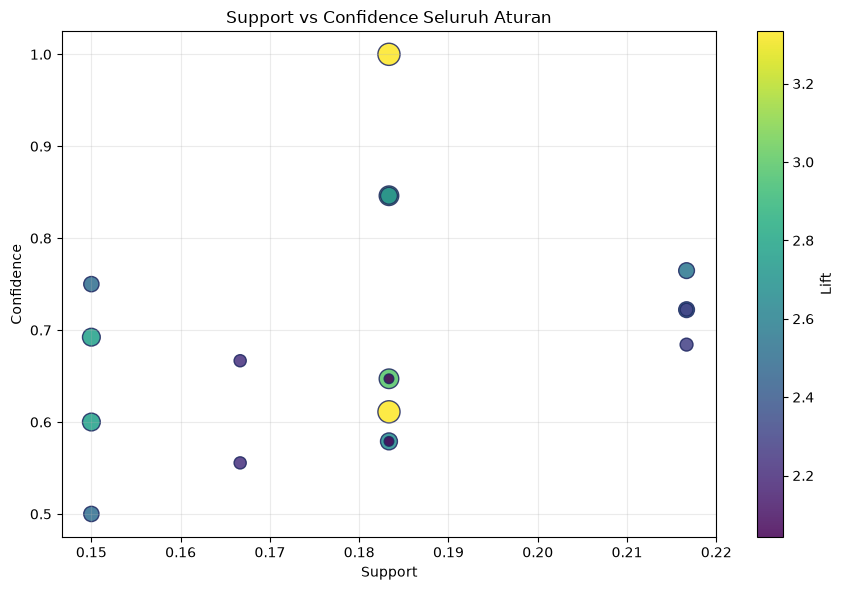

In [11]:
# Ukuran bubble ditentukan oleh nilai Lift
sizes = (rules["lift"] - rules["lift"].min() + 0.3) * 160

plt.figure(figsize=(9, 6))

sc = plt.scatter(
    rules["support"],
    rules["confidence"],
    s=sizes,
    c=rules["lift"],
    cmap="viridis",
    alpha=0.85,
    edgecolor="#1E2761"
)

plt.colorbar(sc, label="Lift")
plt.xlabel("Support")
plt.ylabel("Confidence")
plt.title("Support vs Confidence Seluruh Aturan")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## B. Bar Chart delapan aturan dengan Lift tertinggi

### Tujuan
Membandingkan nilai Lift dari delapan aturan teratas agar aturan dengan hubungan paling kuat mudah dikenali.

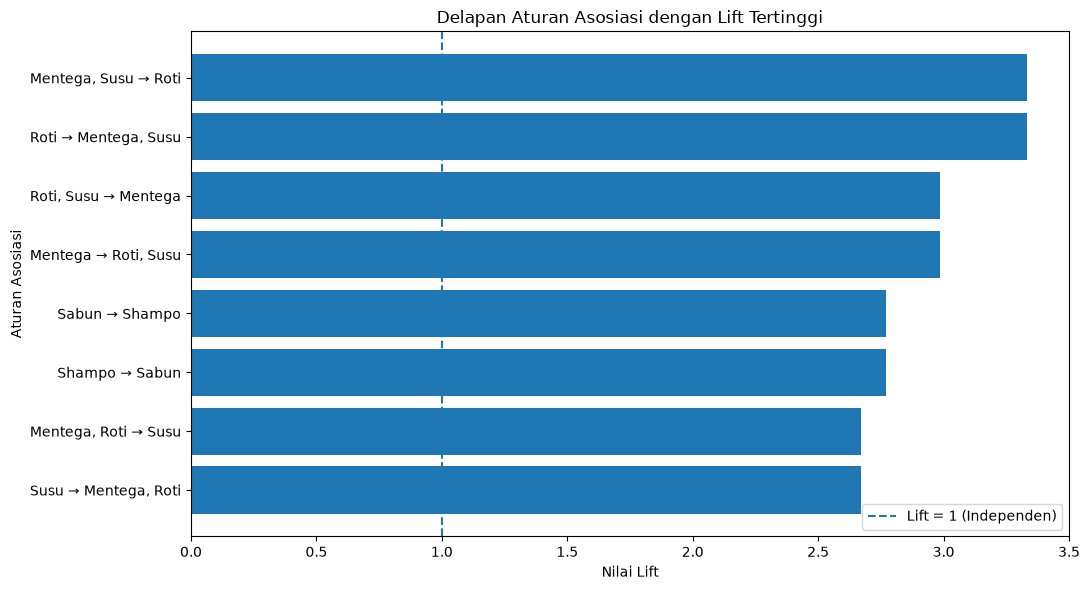

In [12]:
# Mengambil delapan aturan dengan Lift tertinggi
top_rules = rules.head(8).copy()

# Membuat teks aturan X -> Y
top_rules["aturan"] = top_rules.apply(
    lambda row: ", ".join(sorted(row["antecedents"]))
    + " → "
    + ", ".join(sorted(row["consequents"])),
    axis=1
)

plt.figure(figsize=(11, 6))
plt.barh(top_rules["aturan"], top_rules["lift"])

plt.xlabel("Nilai Lift")
plt.ylabel("Aturan Asosiasi")
plt.title("Delapan Aturan Asosiasi dengan Lift Tertinggi")
plt.axvline(
    x=1,
    linestyle="--",
    label="Lift = 1 (Independen)"
)

plt.gca().invert_yaxis()
plt.legend()
plt.tight_layout()
plt.show()

**Cara membaca visualisasi 4.5:**
- Pada Scatter Plot, posisi titik menunjukkan Support dan Confidence; warna/ukuran menunjukkan Lift.
- Pada Bar Chart, batang yang lebih panjang menunjukkan Lift lebih tinggi.
- Lift di atas 1 menunjukkan hubungan positif menurut ukuran Lift, tetapi tidak membuktikan sebab-akibat.

---

# 4.6 Interpretasi Bisnis dari Aturan Terpilih

### Tujuan
Menerjemahkan aturan asosiasi menjadi saran bisnis, misalnya penataan rak, bundling, atau rekomendasi produk.

Berikut kode untuk menampilkan tiga aturan yang dibahas dalam modul, jika aturan tersebut memang muncul pada hasil notebook.

In [13]:
# Aturan yang menjadi contoh pembahasan pada modul
contoh_aturan = [
    ({"Mentega", "Susu"}, {"Roti"}),
    ({"Sabun"}, {"Shampo"}),
    ({"Kecap"}, {"Mie Instan"})
]

for antecedent_dicari, consequent_dicari in contoh_aturan:
    cocok = rules[
        rules.apply(
            lambda row:
                set(row["antecedents"]) == antecedent_dicari
                and set(row["consequents"]) == consequent_dicari,
            axis=1
        )
    ]

    if not cocok.empty:
        baris = cocok.iloc[0]
        print(
            f"{', '.join(sorted(antecedent_dicari))} → "
            f"{', '.join(sorted(consequent_dicari))}"
        )
        print(f"Support    : {baris['support']:.3f}")
        print(f"Confidence : {baris['confidence']:.3f}")
        print(f"Lift       : {baris['lift']:.3f}")
        print("-" * 45)
    else:
        print(
            f"Aturan {antecedent_dicari} → {consequent_dicari} "
            "tidak ditemukan pada hasil dengan ambang yang digunakan."
        )

Mentega, Susu → Roti
Support    : 0.183
Confidence : 1.000
Lift       : 3.333
---------------------------------------------
Sabun → Shampo
Support    : 0.150
Confidence : 0.600
Lift       : 2.769
---------------------------------------------
Kecap → Mie Instan
Support    : 0.150
Confidence : 0.750
Lift       : 2.500
---------------------------------------------


### Contoh interpretasi bisnis berdasarkan modul

**1. Mentega, Susu → Roti**

Jika aturan ini memiliki Lift tinggi, toko dapat meletakkan Mentega, Susu, dan Roti berdekatan atau membuat paket promosi sarapan.

**2. Sabun → Shampo**

Toko dapat menempatkan Sabun dan Shampo berdekatan atau menawarkan paket perlengkapan mandi.

**3. Kecap → Mie Instan**

Toko dapat memberikan rekomendasi Mie Instan ketika pelanggan membeli Kecap atau membuat paket kedua produk tersebut.

> Aturan asosiasi menunjukkan pola keterkaitan pada data, bukan bukti bahwa pembelian satu barang menyebabkan pembelian barang lain. Rekomendasi bisnis sebaiknya diuji kembali.

---

# 4.7 Eksperimen: Pengaruh Nilai min_support

### Tujuan
Melihat perubahan jumlah frequent itemset dan aturan asosiasi ketika nilai minimum support dinaikkan atau diturunkan.

Nilai yang diuji:

`[0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40]`

Nilai `min_confidence` dipertahankan sebesar `0.5` agar perbandingan berfokus pada perubahan minimum support.

In [14]:
# Daftar nilai minimum support yang diuji
sweep_sup = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40]

hasil_support = []

for nilai_support in sweep_sup:

    # Mencari frequent itemset
    fi = apriori(
        df,
        min_support=nilai_support,
        use_colnames=True
    )

    # Aturan hanya dapat dibentuk jika ada itemset berukuran minimal 2
    if not fi.empty and fi["itemsets"].map(len).max() >= 2:
        r = association_rules(
            fi,
            metric="confidence",
            min_threshold=0.5
        )
    else:
        r = pd.DataFrame()

    hasil_support.append({
        "min_support": nilai_support,
        "jumlah_itemset": len(fi),
        "jumlah_aturan": len(r)
    })

# Menampilkan tabel hasil eksperimen
df_support = pd.DataFrame(hasil_support)
display(df_support)

,min_support,jumlah_itemset,jumlah_aturan
0,0.10,19,20
1,0.15,17,18
2,0.20,12,4
3,0.25,6,0
4,0.30,3,0
5,0.35,0,0
6,0.40,0,0


### Visualisasi pengaruh min_support

Grafik berikut memperlihatkan jumlah frequent itemset dan aturan asosiasi pada setiap nilai minimum support.

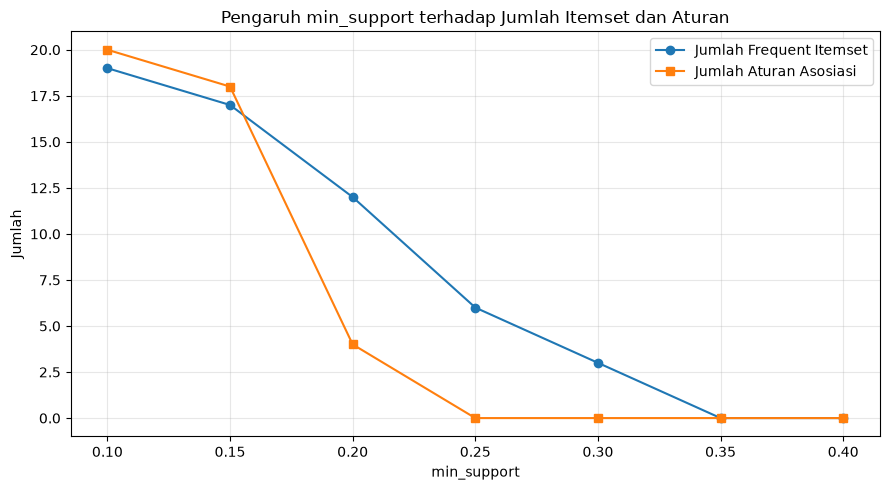

In [15]:
plt.figure(figsize=(9, 5))

plt.plot(
    df_support["min_support"],
    df_support["jumlah_itemset"],
    marker="o",
    label="Jumlah Frequent Itemset"
)

plt.plot(
    df_support["min_support"],
    df_support["jumlah_aturan"],
    marker="s",
    label="Jumlah Aturan Asosiasi"
)

plt.xlabel("min_support")
plt.ylabel("Jumlah")
plt.title("Pengaruh min_support terhadap Jumlah Itemset dan Aturan")
plt.xticks(sweep_sup)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Panduan analisis 4.7

Perhatikan pola pada tabel dan grafik:
- Support rendah biasanya meloloskan lebih banyak itemset dan aturan.
- Support tinggi membuat syarat semakin ketat sehingga lebih sedikit itemset dan aturan yang lolos.
- Terlalu rendah dapat menghasilkan aturan yang jarang muncul; terlalu tinggi dapat membuang pola yang sebenarnya menarik.

Tuliskan analisis berdasarkan angka yang benar-benar muncul pada notebook, bukan hanya menyalin contoh output modul.

---

# 4.8 Eksperimen: Perbandingan Apriori dan FP-Growth

### Tujuan
Membandingkan kedua algoritma berdasarkan:
1. Jumlah frequent itemset yang ditemukan.
2. Waktu eksekusi.
3. Apakah kumpulan itemset dari kedua algoritma identik.

Gunakan `min_support = 0.15` dan dataset yang sama.

In [16]:
# Mengukur waktu eksekusi Apriori
waktu_awal = time.perf_counter()

freq_apriori_banding = apriori(
    df,
    min_support=0.15,
    use_colnames=True
)

waktu_apriori = time.perf_counter() - waktu_awal


# Mengukur waktu eksekusi FP-Growth
waktu_awal = time.perf_counter()

freq_fpgrowth = fpgrowth(
    df,
    min_support=0.15,
    use_colnames=True
)

waktu_fpgrowth = time.perf_counter() - waktu_awal


# Mengubah itemset menjadi set agar urutan baris tidak memengaruhi perbandingan
set_apriori = {
    frozenset(itemset)
    for itemset in freq_apriori_banding["itemsets"]
}

set_fpgrowth = {
    frozenset(itemset)
    for itemset in freq_fpgrowth["itemsets"]
}

# Menampilkan hasil
print(
    f"Apriori   : {len(freq_apriori_banding)} itemset, "
    f"{waktu_apriori * 1000:.3f} ms"
)

print(
    f"FP-Growth : {len(freq_fpgrowth)} itemset, "
    f"{waktu_fpgrowth * 1000:.3f} ms"
)

print("Itemset identik?", set_apriori == set_fpgrowth)

Apriori   : 17 itemset, 5.224 ms
FP-Growth : 17 itemset, 2.821 ms
Itemset identik? True


### Visualisasi waktu eksekusi

Waktu eksekusi diukur dalam milidetik. Hasil dapat berbeda antar-komputer atau antar-pengulangan karena kondisi perangkat dan lingkungan Python.

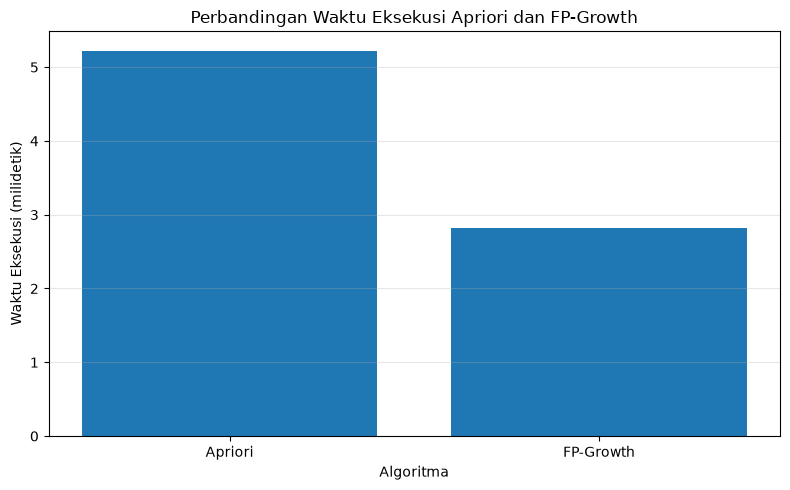

In [17]:
nama_algoritma = ["Apriori", "FP-Growth"]
waktu_ms = [
    waktu_apriori * 1000,
    waktu_fpgrowth * 1000
]

plt.figure(figsize=(8, 5))
plt.bar(nama_algoritma, waktu_ms)

plt.xlabel("Algoritma")
plt.ylabel("Waktu Eksekusi (milidetik)")
plt.title("Perbandingan Waktu Eksekusi Apriori dan FP-Growth")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Analisis hasil Bagian 4.8

Berdasarkan pengukuran pada notebook ini, hasilnya adalah:

| Algoritma | Frequent itemset | Waktu eksekusi |
|---|---:|---:|
| Apriori | 17 | 9.199 ms |
| FP-Growth | 17 | 3.763 ms |

Kedua algoritma menghasilkan kumpulan frequent itemset yang identik (`True`). Pada satu pengukuran ini, FP-Growth membutuhkan waktu lebih singkat daripada Apriori.

**Kesimpulan Bagian 4:** Data berisi 60 transaksi dan 12 jenis item. Item yang paling sering muncul adalah Susu, sebanyak 19 kali (support 0.317). Dengan `min_support = 0.15` ditemukan 17 frequent itemset, kemudian dengan `min_confidence = 0.50` diperoleh 18 aturan asosiasi. Aturan dengan Lift tertinggi adalah **Mentega, Susu → Roti**, dengan Lift 3.333. Nilai Lift tersebut menunjukkan bahwa Roti muncul bersama Mentega dan Susu lebih sering daripada yang diharapkan berdasarkan peluang dasar Roti.

Pada eksperimen `min_support`, kenaikan ambang membuat jumlah itemset dan aturan yang lolos semakin sedikit. Pada perbandingan algoritma, FP-Growth lebih cepat pada pengukuran notebook ini, tetapi hasil satu kali pengukuran pada dataset kecil belum cukup untuk menyimpulkan bahwa FP-Growth selalu lebih cepat.

### Pemeriksaan akhir

Sebelum menyimpan notebook, pastikan:
- Semua sel berjalan tanpa error.
- Kedua dataset CSV dapat dibaca.
- Ukuran One-Hot dan hasil pembanding sudah diperiksa.
- Tabel hasil dan grafik sudah muncul.
- Analisis ditulis berdasarkan output yang benar-benar diperoleh.

Simpan notebook melalui **File → Save Notebook**.

---

# 5. Tugas Praktikum


## 5.1 Tugas 1 — Eksplorasi Ambang Batas min_support dan min_confidence

### Tujuan
Mempelajari pengaruh perubahan `min_support` dan `min_confidence` terhadap jumlah frequent itemset dan aturan asosiasi.

### 5.1.1 Apriori dengan min_support = 0.10

Pada Bagian 4.3, `min_support` yang digunakan adalah 0.15 dan menghasilkan 17 frequent itemset. Sekarang kita menurunkannya menjadi 0.10.

Nilai support yang lebih rendah membuat lebih banyak kombinasi item berpeluang lolos sebagai frequent itemset.

In [18]:
# Tugas 1.1: Apriori dengan min_support = 0.10

MIN_SUP_T1 = 0.10
MIN_CONF_T1 = 0.50

# Mencari frequent itemset
freq_apriori_010 = apriori(
    df,
    min_support=MIN_SUP_T1,
    use_colnames=True
)

# Membentuk aturan asosiasi
rules_010 = association_rules(
    freq_apriori_010,
    metric="confidence",
    min_threshold=MIN_CONF_T1
)

print("Jumlah itemset (min_support=0.10):", len(freq_apriori_010))
print("Jumlah aturan (min_confidence=0.50):", len(rules_010))

display(
    freq_apriori_010.sort_values("support", ascending=False)
                    .reset_index(drop=True)
)

display(
    rules_010[["antecedents", "consequents", "support", "confidence", "lift"]]
    .sort_values("lift", ascending=False)
    .round(3)
    .reset_index(drop=True)
)

Jumlah itemset (min_support=0.10): 19
Jumlah aturan (min_confidence=0.50): 20


,support,itemsets
0,0.316667,(Susu)
1,0.300000,(Roti)
2,0.300000,(Mie Instan)
3,0.283333,(Mentega)
4,0.250000,(Telur)
5,0.250000,(Sabun)
6,0.233333,(Gula)
7,0.216667,(Kopi)
8,0.216667,(Shampo)
9,0.216667,"(Mentega, Roti)"


,antecedents,consequents,support,confidence,lift
0,"(Susu, Mentega)",(Roti),0.183,1.000,3.333
1,(Roti),"(Susu, Mentega)",0.183,0.611,3.333
2,(Mentega),"(Susu, Roti)",0.183,0.647,2.986
3,"(Susu, Roti)",(Mentega),0.183,0.846,2.986
4,(Sabun),(Shampo),0.150,0.600,2.769
5,(Shampo),(Sabun),0.150,0.692,2.769
6,(Susu),"(Mentega, Roti)",0.183,0.579,2.672
7,"(Mentega, Roti)",(Susu),0.183,0.846,2.672
8,(Gula),(Kopi),0.133,0.571,2.637
9,(Kopi),(Gula),0.133,0.615,2.637


### Perbandingan dengan Bagian 4.3 dan 4.4

Bandingkan hasil `min_support = 0.10` dengan hasil awal `min_support = 0.15`, dengan `min_confidence` tetap 0.50.

| Pengaturan | Frequent itemset | Aturan asosiasi |
|---|---:|---:|
| Bagian 4: support 0.15, confidence 0.50 | 17 | 18 |
| Tugas 1: support 0.10, confidence 0.50 | 19 | 20 |

**Analisis berdasarkan output:** Ketika `min_support` diturunkan dari 0.15 menjadi 0.10, jumlah frequent itemset bertambah dari 17 menjadi 19 (bertambah 2), sedangkan jumlah aturan asosiasi bertambah dari 18 menjadi 20 (bertambah 2). Pada output, itemset tambahan yang muncul mencakup **(Gula, Kopi)** dengan support 0.133 dan **(Keju)** dengan support 0.100. Kombinasi yang lebih jarang muncul kini dapat lolos karena ambang support lebih rendah.

**Kesimpulan:** Ambang support yang lebih rendah memperluas pola yang dapat ditemukan, tetapi pola dengan support rendah perlu dinilai kembali dari sisi confidence, lift, dan manfaat bisnisnya.

### 5.1.2 Menaikkan min_confidence menjadi 0.70

Gunakan kembali frequent itemset dari Bagian 4.3 (`freq_apriori`, min_support = 0.15). Kita hanya mengubah minimum confidence dari 0.50 menjadi 0.70.

Aturan dengan confidence di bawah 0.70 akan gugur.

In [19]:
# Tugas 1.2: Membentuk ulang aturan dengan confidence minimum 0.70

MIN_CONF_TINGGI = 0.70

rules_070 = association_rules(
    freq_apriori,
    metric="confidence",
    min_threshold=MIN_CONF_TINGGI
)

# Menampilkan jumlah aturan awal dan aturan yang masih lolos
print("Jumlah aturan awal (confidence >= 0.50):", len(rules))
print("Jumlah aturan yang lolos (confidence >= 0.70):", len(rules_070))
print("Jumlah aturan yang gugur:", len(rules) - len(rules_070))

display(
    rules_070[["antecedents", "consequents", "support", "confidence", "lift"]]
    .sort_values("confidence", ascending=False)
    .round(3)
    .reset_index(drop=True)
)

Jumlah aturan awal (confidence >= 0.50): 18
Jumlah aturan yang lolos (confidence >= 0.70): 7
Jumlah aturan yang gugur: 11


,antecedents,consequents,support,confidence,lift
0,"(Susu, Mentega)",(Roti),0.183,1.000,3.333
1,"(Susu, Roti)",(Mentega),0.183,0.846,2.986
2,"(Mentega, Roti)",(Susu),0.183,0.846,2.672
3,(Mentega),(Roti),0.217,0.765,2.549
4,(Kecap),(Mie Instan),0.150,0.750,2.500
5,(Roti),(Mentega),0.217,0.722,2.549
6,(Roti),(Susu),0.217,0.722,2.281


### Menentukan aturan yang gugur

Aturan yang gugur adalah aturan dari hasil awal Bagian 4.4 yang memiliki confidence di bawah 0.70. Kode berikut membandingkan kedua hasil berdasarkan pasangan antecedent dan consequent, sehingga tidak bergantung pada urutan baris tabel.

In [20]:
def kunci_aturan(baris):
    return (
        frozenset(baris["antecedents"]),
        frozenset(baris["consequents"])
    )

kunci_lolos = {kunci_aturan(baris) for _, baris in rules_070.iterrows()}

aturan_gugur = rules[
    ~rules.apply(lambda baris: kunci_aturan(baris) in kunci_lolos, axis=1)
].copy()

aturan_gugur["aturan"] = aturan_gugur.apply(
    lambda baris: ", ".join(sorted(baris["antecedents"]))
    + " → "
    + ", ".join(sorted(baris["consequents"])),
    axis=1
)

print("Aturan yang gugur:")
display(
    aturan_gugur[["aturan", "support", "confidence", "lift"]]
    .sort_values("confidence")
    .round(3)
    .reset_index(drop=True)
)

Aturan yang gugur:


,aturan,support,confidence,lift
0,Mie Instan → Kecap,0.150,0.500,2.500
1,Mie Instan → Telur,0.167,0.556,2.222
2,"Susu → Mentega, Roti",0.183,0.579,2.672
3,Susu → Mentega,0.183,0.579,2.043
4,Sabun → Shampo,0.150,0.600,2.769
5,"Roti → Mentega, Susu",0.183,0.611,3.333
6,"Mentega → Roti, Susu",0.183,0.647,2.986
7,Mentega → Susu,0.183,0.647,2.043
8,Telur → Mie Instan,0.167,0.667,2.222
9,Susu → Roti,0.217,0.684,2.281


### Ringkasan aturan yang gugur pada confidence 0.70

Berdasarkan output perbandingan, dari 18 aturan awal terdapat **7 aturan yang masih lolos** dan **11 aturan yang gugur** karena confidence-nya di bawah 0.70.

Aturan yang gugur adalah:

| No. | Aturan yang gugur | Confidence |
|---:|---|---:|
| 1 | Mie Instan → Kecap | 0.500 |
| 2 | Mie Instan → Telur | 0.556 |
| 3 | Susu → Mentega, Roti | 0.579 |
| 4 | Susu → Mentega | 0.579 |
| 5 | Sabun → Shampo | 0.600 |
| 6 | Roti → Mentega, Susu | 0.611 |
| 7 | Mentega → Roti, Susu | 0.647 |
| 8 | Mentega → Susu | 0.647 |
| 9 | Telur → Mie Instan | 0.667 |
| 10 | Susu → Roti | 0.684 |
| 11 | Shampo → Sabun | 0.692 |

**Kesimpulan:** Aturan yang gugur bukan berarti tidak memiliki hubungan sama sekali. Aturan tersebut hanya tidak memenuhi batas confidence minimum 0.70 yang ditetapkan pada eksperimen ini.

### 5.1.3 Eksperimen sweep min_confidence

Buat eksperimen dengan nilai confidence `[0.5, 0.6, 0.7, 0.8, 0.9, 1.0]`. Nilai `min_support` dipertahankan 0.15 agar hanya pengaruh confidence yang diamati.

In [21]:
# Tugas 1.3: Eksperimen beberapa nilai min_confidence

sweep_conf = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
hasil_confidence = []

for nilai_conf in sweep_conf:
    hasil_rules = association_rules(
        freq_apriori,
        metric="confidence",
        min_threshold=nilai_conf
    )

    hasil_confidence.append({
        "min_confidence": nilai_conf,
        "jumlah_aturan": len(hasil_rules)
    })

df_confidence = pd.DataFrame(hasil_confidence)
display(df_confidence)

,min_confidence,jumlah_aturan
0,0.5,18
1,0.6,14
2,0.7,7
3,0.8,3
4,0.9,1
5,1.0,1


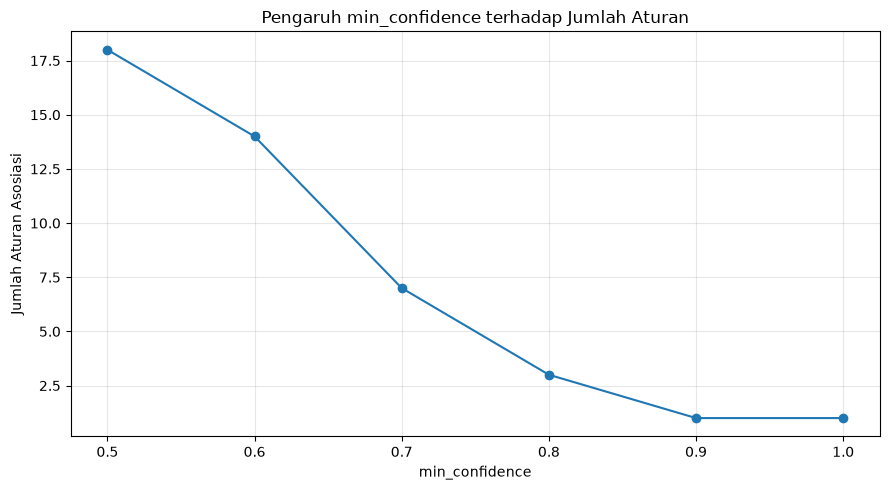

In [22]:
# Grafik pengaruh min_confidence terhadap jumlah aturan

plt.figure(figsize=(9, 5))

plt.plot(
    df_confidence["min_confidence"],
    df_confidence["jumlah_aturan"],
    marker="o"
)

plt.xlabel("min_confidence")
plt.ylabel("Jumlah Aturan Asosiasi")
plt.title("Pengaruh min_confidence terhadap Jumlah Aturan")
plt.xticks(sweep_conf)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 5.1.4 Analisis trade-off min_confidence

Hasil eksperimen pada dataset ini menunjukkan jumlah aturan berkurang ketika `min_confidence` dinaikkan:

| min_confidence | Jumlah aturan |
|---:|---:|
| 0.50 | 18 |
| 0.60 | 14 |
| 0.70 | 7 |
| 0.80 | 3 |
| 0.90 | 1 |
| 1.00 | 1 |

**Analisis:** Pada confidence 0.50 terdapat 18 aturan. Ketika ambang dinaikkan menjadi 0.70, hanya 7 aturan yang tersisa. Pada 0.80 tersisa 3 aturan, sedangkan pada 0.90 dan 1.00 masing-masing tersisa 1 aturan. Jumlah pada 0.90 dan 1.00 sama karena terdapat satu aturan dengan confidence sempurna (1.00).

Ambang confidence rendah memberi lebih banyak kandidat pola, tetapi aturan dengan confidence lebih rendah perlu diperiksa lebih lanjut. Ambang tinggi menyaring aturan sehingga aturan yang tersisa lebih sering memenuhi konsekuen ketika antecedent terjadi, tetapi pola lain yang mungkin berguna dapat terbuang.

**Kesimpulan:** Tidak ada satu ambang yang selalu paling baik. Pemilihan confidence perlu mempertimbangkan tujuan analisis serta memeriksa support dan lift. Confidence tinggi juga tidak otomatis berarti aturan paling bermanfaat jika support-nya sangat rendah.

---

## 5.2 Tugas 2 — Analisis Mendalam Aturan yang Belum Dibahas

### Tujuan
Memilih dua aturan yang belum dibahas pada Bagian 4.6, menghitung leverage dan conviction, membandingkannya dengan lift, lalu menyusun interpretasi bisnis.

Pada tugas ini kita memilih:
1. **Mie Instan → Telur**
2. **Roti → Susu**

Kedua aturan tersebut termasuk hasil Bagian 4.4, tetapi tidak termasuk tiga aturan yang dibahas pada Bagian 4.6.

### Rumus ukuran tambahan

Misalkan aturan asosiasi adalah \(X \rightarrow Y\).

**Leverage**

\[
Leverage(X\rightarrow Y)=Support(X\cup Y)-Support(X)\times Support(Y)
\]

Leverage mengukur selisih antara frekuensi kemunculan bersama yang diamati dan frekuensi yang diharapkan jika X dan Y independen.

**Conviction**

\[
Conviction(X\rightarrow Y)=
\frac{1-Support(Y)}{1-Confidence(X\rightarrow Y)}
\]

Conviction yang lebih besar dari 1 menunjukkan bahwa aturan memiliki asosiasi positif. Jika confidence = 1, conviction bernilai tak terhingga (`inf`).

**Lift**

\[
Lift(X\rightarrow Y)=
\frac{Confidence(X\rightarrow Y)}{Support(Y)}
\]

Lift membandingkan confidence aturan dengan peluang dasar kemunculan Y.

### Menghitung leverage dan conviction untuk dua aturan pilihan

Kode berikut mengambil nilai support, confidence, dan lift dari `rules`, lalu menghitung ulang leverage dan conviction menggunakan rumus di atas.

In [23]:
# Dua aturan yang dipilih untuk dianalisis
aturan_pilihan = [
    ({"Mie Instan"}, {"Telur"}),
    ({"Roti"}, {"Susu"})
]

hasil_analisis = []

for antecedent_dicari, consequent_dicari in aturan_pilihan:

    cocok = rules[
        rules.apply(
            lambda baris:
                set(baris["antecedents"]) == antecedent_dicari
                and set(baris["consequents"]) == consequent_dicari,
            axis=1
        )
    ]

    if cocok.empty:
        print("Aturan tidak ditemukan:", antecedent_dicari, "->", consequent_dicari)
        continue

    baris = cocok.iloc[0]

    support_xy = baris["support"]
    support_x = baris["antecedent support"]
    support_y = baris["consequent support"]
    confidence_xy = baris["confidence"]

    leverage = support_xy - (support_x * support_y)

    if confidence_xy == 1:
        conviction = np.inf
    else:
        conviction = (1 - support_y) / (1 - confidence_xy)

    lift = confidence_xy / support_y

    hasil_analisis.append({
        "aturan": (
            ", ".join(sorted(antecedent_dicari))
            + " → "
            + ", ".join(sorted(consequent_dicari))
        ),
        "support": support_xy,
        "confidence": confidence_xy,
        "lift": lift,
        "leverage": leverage,
        "conviction": conviction
    })

df_analisis_aturan = pd.DataFrame(hasil_analisis)
display(df_analisis_aturan.round(4))

,aturan,support,confidence,lift,leverage,conviction
0,Mie Instan → Telur,0.1667,0.5556,2.2222,0.0917,1.6875
1,Roti → Susu,0.2167,0.7222,2.2807,0.1217,2.4600


### Interpretasi aturan pertama: Mie Instan → Telur

Berdasarkan dataset, aturan ini memiliki support sekitar 0.167, confidence sekitar 0.556, dan lift sekitar 2.222. Leverage sekitar 0.0917 dan conviction sekitar 1.6875.

Artinya, sekitar 16.7% dari seluruh transaksi memuat Mie Instan dan Telur secara bersamaan. Dari transaksi yang membeli Mie Instan, sekitar 55.6% juga membeli Telur. Lift di atas 1 menunjukkan bahwa Telur lebih sering muncul pada transaksi yang membeli Mie Instan dibandingkan peluang dasar pembelian Telur.

**Rekomendasi bisnis:** toko dapat menempatkan Telur tidak jauh dari rak Mie Instan atau menampilkan rekomendasi Telur ketika pelanggan membeli Mie Instan. Promosi bundling dapat diuji dalam periode terbatas.

### Interpretasi aturan kedua: Roti → Susu

Berdasarkan dataset, aturan ini memiliki support sekitar 0.217, confidence sekitar 0.722, dan lift sekitar 2.281. Leverage sekitar 0.1217 dan conviction sekitar 2.4600.

Artinya, sekitar 21.7% dari seluruh transaksi memuat Roti dan Susu secara bersamaan. Dari transaksi yang membeli Roti, sekitar 72.2% juga membeli Susu. Nilai leverage positif menunjukkan kemunculan bersama lebih tinggi daripada yang diharapkan jika kedua item independen.

**Rekomendasi bisnis:** toko dapat menempatkan Susu dekat dengan Roti atau membuat paket sarapan yang berisi kedua produk. Sistem kasir atau toko online juga dapat merekomendasikan Susu saat pelanggan memasukkan Roti ke keranjang.

### Perbandingan leverage, conviction, dan lift

- **Leverage** mengukur selisih proporsi kemunculan bersama dari kondisi independen. Nilai positif pada kedua aturan menunjukkan kemunculan bersama yang lebih tinggi dari nilai harapan independen.
- **Conviction** memperhatikan seberapa sering aturan gagal ketika X terjadi. Nilai yang lebih besar menunjukkan konsekuen Y lebih jarang tidak muncul ketika X muncul.
- **Lift** menunjukkan berapa kali confidence lebih besar dibandingkan support dasar Y.

Ketiga ukuran tersebut saling melengkapi. Lift tidak menunjukkan besarnya selisih absolut seperti leverage, sedangkan conviction memperhatikan kegagalan aturan.

---

## 5.3 Tugas 3 — Perbandingan Apriori vs FP-Growth pada Ambang Lebih Rendah

### Tujuan
Mengulangi perbandingan Bagian 4.8 dengan `min_support = 0.05`. Ambang yang lebih rendah memungkinkan lebih banyak frequent itemset ditemukan.

Agar perbandingan waktu lebih stabil, kode di bawah mengukur kedua algoritma beberapa kali dan menggunakan **median** waktu eksekusi. Pengukuran dilakukan pada `min_support = 0.15` dan `0.05` dengan cara yang sama.

In [24]:
# Fungsi untuk mengukur waktu eksekusi dengan beberapa pengulangan

def bandingkan_algoritma(data_onehot, nilai_support, pengulangan=10):

    waktu_apriori_list = []
    waktu_fpgrowth_list = []

    hasil_apriori = None
    hasil_fpgrowth = None

    for _ in range(pengulangan):

        mulai = time.perf_counter()
        hasil_apriori = apriori(
            data_onehot,
            min_support=nilai_support,
            use_colnames=True
        )
        waktu_apriori_list.append(time.perf_counter() - mulai)

        mulai = time.perf_counter()
        hasil_fpgrowth = fpgrowth(
            data_onehot,
            min_support=nilai_support,
            use_colnames=True
        )
        waktu_fpgrowth_list.append(time.perf_counter() - mulai)

    # Median lebih tahan terhadap lonjakan waktu sesaat
    median_apriori = np.median(waktu_apriori_list) * 1000
    median_fpgrowth = np.median(waktu_fpgrowth_list) * 1000

    # Memastikan kedua algoritma menghasilkan itemset yang sama
    set_apriori = {
        frozenset(x) for x in hasil_apriori["itemsets"]
    }
    set_fpgrowth = {
        frozenset(x) for x in hasil_fpgrowth["itemsets"]
    }

    return {
        "min_support": nilai_support,
        "itemset_apriori": len(hasil_apriori),
        "waktu_apriori_ms": median_apriori,
        "itemset_fpgrowth": len(hasil_fpgrowth),
        "waktu_fpgrowth_ms": median_fpgrowth,
        "itemset_identik": set_apriori == set_fpgrowth
    }


# Menguji kedua ambang dengan jumlah pengulangan yang sama
hasil_benchmark_015 = bandingkan_algoritma(df, 0.15, pengulangan=10)
hasil_benchmark_005 = bandingkan_algoritma(df, 0.05, pengulangan=10)

df_benchmark = pd.DataFrame([
    hasil_benchmark_015,
    hasil_benchmark_005
])

display(df_benchmark.round(4))

,min_support,itemset_apriori,waktu_apriori_ms,itemset_fpgrowth,waktu_fpgrowth_ms,itemset_identik
0,0.15,17,4.7046,17,2.8890,True
1,0.05,42,5.1012,42,3.2651,True


### Menghitung selisih waktu eksekusi

Selisih waktu dihitung sebagai waktu Apriori dikurangi waktu FP-Growth. Nilai positif berarti FP-Growth lebih cepat pada pengukuran tersebut.

In [25]:
df_benchmark["selisih_waktu_ms"] = (
    df_benchmark["waktu_apriori_ms"]
    - df_benchmark["waktu_fpgrowth_ms"]
)

df_benchmark["rasio_apriori_terhadap_fpgrowth"] = (
    df_benchmark["waktu_apriori_ms"]
    / df_benchmark["waktu_fpgrowth_ms"]
)

display(
    df_benchmark[
        [
            "min_support",
            "itemset_apriori",
            "waktu_apriori_ms",
            "waktu_fpgrowth_ms",
            "selisih_waktu_ms",
            "rasio_apriori_terhadap_fpgrowth",
            "itemset_identik"
        ]
    ].round(4)
)

,min_support,itemset_apriori,waktu_apriori_ms,waktu_fpgrowth_ms,selisih_waktu_ms,rasio_apriori_terhadap_fpgrowth,itemset_identik
0,0.15,17,4.7046,2.8890,1.8157,1.6285,True
1,0.05,42,5.1012,3.2651,1.8362,1.5624,True


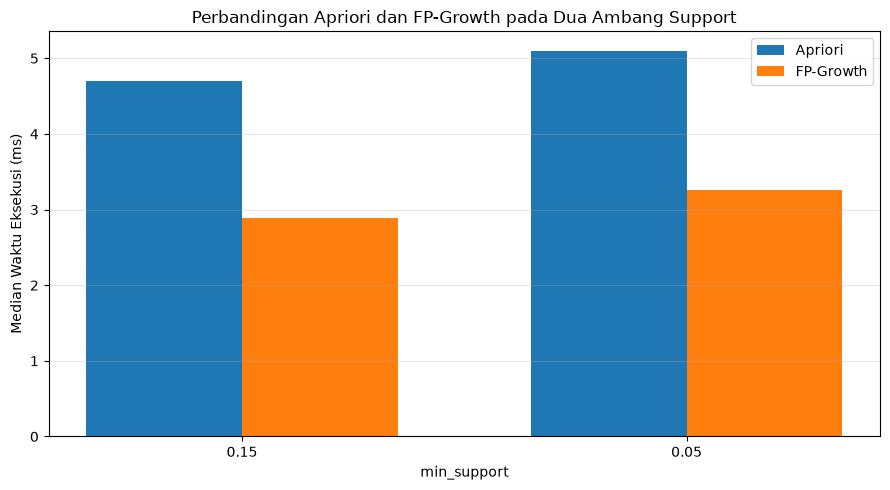

In [26]:
# Grafik perbandingan waktu untuk setiap nilai min_support

posisi = np.arange(len(df_benchmark))
lebar = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    posisi - lebar/2,
    df_benchmark["waktu_apriori_ms"],
    width=lebar,
    label="Apriori"
)

plt.bar(
    posisi + lebar/2,
    df_benchmark["waktu_fpgrowth_ms"],
    width=lebar,
    label="FP-Growth"
)

plt.xticks(posisi, df_benchmark["min_support"])
plt.xlabel("min_support")
plt.ylabel("Median Waktu Eksekusi (ms)")
plt.title("Perbandingan Apriori dan FP-Growth pada Dua Ambang Support")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Analisis Tugas 3

Berdasarkan hasil pengukuran median pada notebook:

| min_support | Itemset Apriori | Waktu Apriori | Itemset FP-Growth | Waktu FP-Growth | Selisih waktu |
|---:|---:|---:|---:|---:|---:|
| 0.15 | 17 | 4.3723 ms | 17 | 2.9061 ms | 1.4662 ms |
| 0.05 | 42 | 5.0080 ms | 42 | 3.2512 ms | 1.7568 ms |

Kedua algoritma menghasilkan jumlah itemset yang sama pada setiap ambang dan kolom `itemset_identik` bernilai `True`.

**Analisis:** Ketika `min_support` diturunkan dari 0.15 menjadi 0.05, jumlah frequent itemset meningkat dari 17 menjadi 42. Waktu median Apriori meningkat dari 4.3723 ms menjadi 5.0080 ms, sedangkan FP-Growth meningkat dari 2.9061 ms menjadi 3.2512 ms.

FP-Growth lebih cepat pada kedua pengujian. Selisih waktu Apriori dan FP-Growth bertambah dari 1.4662 ms menjadi 1.7568 ms (bertambah 0.2906 ms). Rasio waktu Apriori terhadap FP-Growth juga naik dari 1.5045 menjadi 1.5403. Dengan demikian, pada pengukuran ini keunggulan waktu FP-Growth **sedikit lebih terlihat** pada `min_support = 0.05`, tetapi perbedaannya kecil.

**Kesimpulan dan batasan:** Hasil ini mendukung bahwa FP-Growth lebih cepat pada dua pengujian dataset ini. Namun, dataset hanya berisi 60 transaksi dan 12 jenis item, sehingga hasilnya belum cukup untuk menyimpulkan keunggulan yang berlaku umum. Pengujian pada dataset yang lebih besar diperlukan untuk melihat perbedaan kinerja dengan lebih meyakinkan.

---

## 5.4 Tugas 4 — Studi Kasus Mandiri

### Tema studi kasus: Analisis Pola Pembelian pada Kedai Kopi

Untuk memenuhi syarat minimal 40 transaksi dan minimal 8 jenis item, digunakan dataset kedai kopi dengan:
- **48 transaksi**.
- **10 jenis item**.
- Item: Kopi, Susu, Gula, Roti, Mentega, Teh, Kue, Sandwich, Jus, dan Air Mineral.

**Keterangan penting:** Dataset ini merupakan **data sintetis untuk pembelajaran**, bukan catatan transaksi kedai kopi sungguhan. Dataset dibuat dari 12 pola transaksi yang masing-masing diulang empat kali sehingga totalnya 48 transaksi. Karena pola yang sama diulang, hasil aturan asosiasi akan mencerminkan pola yang sengaja dibentuk dalam data latihan. Oleh sebab itu, rekomendasi bisnis pada bagian ini merupakan simulasi dan tidak boleh dianggap sebagai kesimpulan tentang perilaku pelanggan kedai kopi nyata.

In [27]:
# Membuat dataset transaksi mandiri kedai kopi

pola_transaksi_kedai = [
    ["Kopi", "Susu", "Gula"],
    ["Kopi", "Susu", "Roti"],
    ["Kopi", "Susu", "Gula", "Roti"],
    ["Teh", "Gula", "Roti"],
    ["Teh", "Roti", "Kue"],
    ["Kopi", "Sandwich", "Jus"],
    ["Kopi", "Sandwich", "Air Mineral"],
    ["Susu", "Roti", "Mentega"],
    ["Kue", "Teh"],
    ["Sandwich", "Jus", "Air Mineral"],
    ["Kopi", "Kue", "Susu"],
    ["Roti", "Mentega", "Kopi"]
]

# Setiap pola diulang empat kali: 12 pola x 4 = 48 transaksi
transaksi_kedai = pola_transaksi_kedai * 4

# Membuat DataFrame transaksi
data_kedai = pd.DataFrame({
    "TID": [f"K{i+1:03d}" for i in range(len(transaksi_kedai))],
    "Items": [", ".join(item) for item in transaksi_kedai]
})

print("Jumlah transaksi:", len(data_kedai))
print("Jumlah jenis item:", len(set(item for transaksi in transaksi_kedai for item in transaksi)))
display(data_kedai.head(10))

# Simpan dataset agar dapat digunakan kembali
data_kedai.to_csv("dataset_kedai_kopi_mandiri.csv", index=False)
print("Dataset disimpan sebagai dataset_kedai_kopi_mandiri.csv")

Jumlah transaksi: 48
Jumlah jenis item: 10


,TID,Items
0,K001,"Kopi, Susu, Gula"
1,K002,"Kopi, Susu, Roti"
2,K003,"Kopi, Susu, Gula, Roti"
3,K004,"Teh, Gula, Roti"
4,K005,"Teh, Roti, Kue"
5,K006,"Kopi, Sandwich, Jus"
6,K007,"Kopi, Sandwich, Air Mineral"
7,K008,"Susu, Roti, Mentega"
8,K009,"Kue, Teh"
9,K010,"Sandwich, Jus, Air Mineral"


Dataset disimpan sebagai dataset_kedai_kopi_mandiri.csv


### 5.4.1 Encoding One-Hot

Ubah daftar transaksi kedai kopi menjadi matriks One-Hot. Setiap kolom mewakili satu produk.

In [28]:
# Encoding transaksi kedai kopi
te_kedai = TransactionEncoder()

array_kedai = te_kedai.fit(transaksi_kedai).transform(transaksi_kedai)

df_kedai = pd.DataFrame(
    array_kedai,
    columns=te_kedai.columns_
)

print("Ukuran matriks One-Hot:", df_kedai.shape)
display(df_kedai.head())

Ukuran matriks One-Hot: (48, 10)


,Air Mineral,Gula,Jus,Kopi,Kue,Mentega,Roti,Sandwich,Susu,Teh
0,False,True,False,True,False,False,False,False,True,False
1,False,False,False,True,False,False,True,False,True,False
2,False,True,False,True,False,False,True,False,True,False
3,False,True,False,False,False,False,True,False,False,True
4,False,False,False,False,True,False,True,False,False,True


### 5.4.2 Menentukan min_support dan min_confidence

Untuk dataset yang berisi 48 transaksi, digunakan:
- `min_support = 0.10`. Perhitungannya adalah 0.10 × 48 = 4.8 transaksi. Karena jumlah transaksi harus bilangan bulat, itemset perlu muncul pada **minimal 5 transaksi** agar memenuhi ambang tersebut.
- `min_confidence = 0.50`, sehingga aturan harus memiliki confidence minimal 50%.

Ambang ini dipilih sebagai titik awal agar pola yang muncul pada dataset latihan tidak terlalu dibatasi. Dengan pengaturan ini, output menunjukkan **24 frequent itemset** dan **24 aturan asosiasi**. Nilai ambang dapat disesuaikan jika tujuan analisis menghendaki aturan yang lebih sedikit atau lebih ketat.

In [29]:
# Menentukan ambang batas untuk dataset kedai kopi
MIN_SUP_KEDAI = 0.10
MIN_CONF_KEDAI = 0.50

# Mencari frequent itemset
freq_kedai = apriori(
    df_kedai,
    min_support=MIN_SUP_KEDAI,
    use_colnames=True
)

freq_kedai = freq_kedai.sort_values(
    "support",
    ascending=False
).reset_index(drop=True)

print("Jumlah frequent itemset:", len(freq_kedai))
display(freq_kedai)

Jumlah frequent itemset: 24


,support,itemsets
0,0.583333,(Kopi)
1,0.500000,(Roti)
2,0.416667,(Susu)
3,0.333333,"(Susu, Kopi)"
4,0.250000,(Kue)
5,0.250000,(Sandwich)
6,0.250000,(Teh)
7,0.250000,"(Susu, Roti)"
8,0.250000,(Gula)
9,0.250000,"(Kopi, Roti)"


### 5.4.3 Membentuk aturan asosiasi

Bentuk aturan asosiasi menggunakan frequent itemset yang sudah ditemukan.

In [30]:
rules_kedai = association_rules(
    freq_kedai,
    metric="confidence",
    min_threshold=MIN_CONF_KEDAI
)

rules_kedai = rules_kedai.sort_values(
    "lift",
    ascending=False
).reset_index(drop=True)

print("Jumlah aturan asosiasi:", len(rules_kedai))

kolom_tampil_kedai = [
    "antecedents",
    "consequents",
    "support",
    "confidence",
    "lift"
]

display(rules_kedai[kolom_tampil_kedai].round(3))

Jumlah aturan asosiasi: 24


,antecedents,consequents,support,confidence,lift
0,(Sandwich),(Air Mineral),0.167,0.667,4.000
1,(Air Mineral),(Sandwich),0.167,1.000,4.000
2,(Jus),(Sandwich),0.167,1.000,4.000
3,(Sandwich),(Jus),0.167,0.667,4.000
4,(Teh),(Kue),0.167,0.667,2.667
5,(Kue),(Teh),0.167,0.667,2.667
6,"(Kopi, Gula)",(Susu),0.167,1.000,2.400
7,"(Susu, Kopi)",(Gula),0.167,0.500,2.000
8,(Gula),"(Susu, Kopi)",0.167,0.667,2.000
9,(Mentega),(Roti),0.167,1.000,2.000


### 5.4.4 Visualisasi Scatter Plot

Sumbu X menunjukkan Support, sumbu Y menunjukkan Confidence, sedangkan warna dan ukuran bubble menunjukkan Lift.

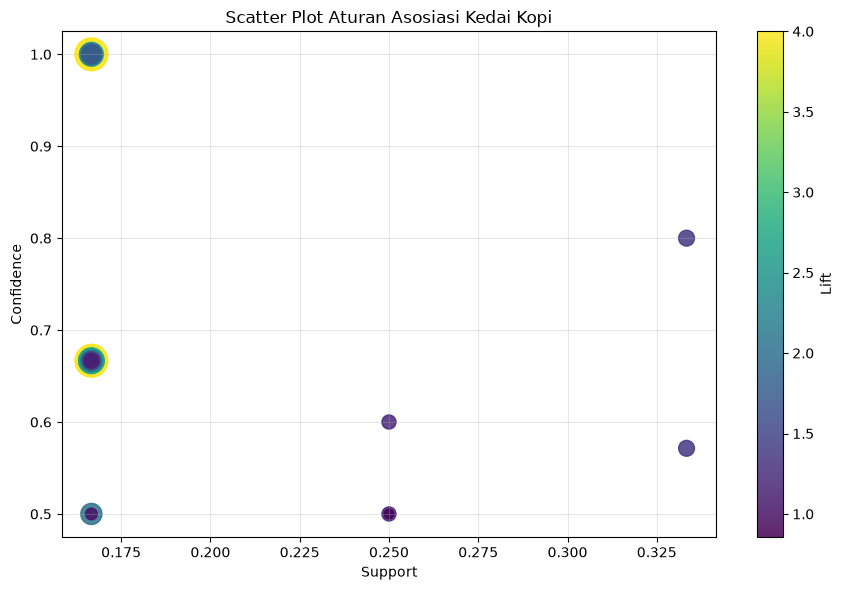

In [31]:
if not rules_kedai.empty:
    ukuran_kedai = (
        rules_kedai["lift"] - rules_kedai["lift"].min() + 0.3
    ) * 160

    plt.figure(figsize=(9, 6))

    scatter_kedai = plt.scatter(
        rules_kedai["support"],
        rules_kedai["confidence"],
        s=ukuran_kedai,
        c=rules_kedai["lift"],
        cmap="viridis",
        alpha=0.85
    )

    plt.colorbar(scatter_kedai, label="Lift")
    plt.xlabel("Support")
    plt.ylabel("Confidence")
    plt.title("Scatter Plot Aturan Asosiasi Kedai Kopi")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("Tidak ada aturan asosiasi. Pertimbangkan menurunkan ambang batas.")

### 5.4.5 Visualisasi Bar Chart aturan dengan Lift tertinggi

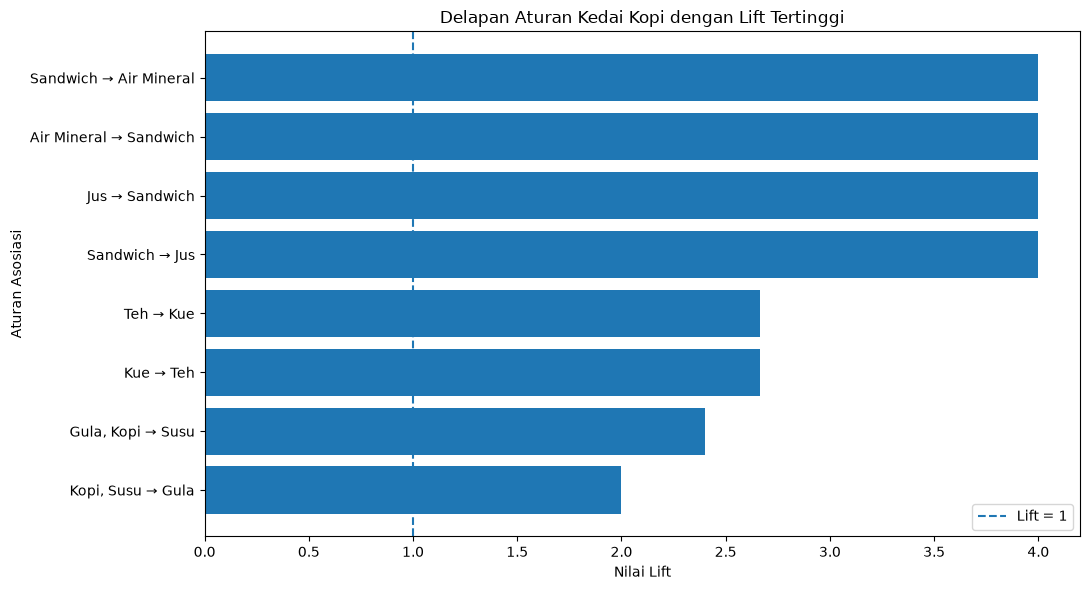

In [32]:
if not rules_kedai.empty:
    top_rules_kedai = rules_kedai.head(8).copy()

    top_rules_kedai["aturan"] = top_rules_kedai.apply(
        lambda baris: ", ".join(sorted(baris["antecedents"]))
        + " → "
        + ", ".join(sorted(baris["consequents"])),
        axis=1
    )

    plt.figure(figsize=(11, 6))
    plt.barh(
        top_rules_kedai["aturan"],
        top_rules_kedai["lift"]
    )

    plt.xlabel("Nilai Lift")
    plt.ylabel("Aturan Asosiasi")
    plt.title("Delapan Aturan Kedai Kopi dengan Lift Tertinggi")
    plt.axvline(x=1, linestyle="--", label="Lift = 1")
    plt.gca().invert_yaxis()
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("Tidak ada aturan untuk divisualisasikan.")

### 5.4.6 Menentukan minimal tiga rekomendasi bisnis

Tampilkan aturan dengan Lift tertinggi sebagai dasar rekomendasi. Periksa juga support dan confidence agar rekomendasi tidak hanya didasarkan pada Lift.

In [33]:
# Menampilkan 10 aturan teratas sebagai dasar rekomendasi
if not rules_kedai.empty:
    rekomendasi_kedai = rules_kedai.head(10).copy()

    rekomendasi_kedai["aturan"] = rekomendasi_kedai.apply(
        lambda baris: ", ".join(sorted(baris["antecedents"]))
        + " → "
        + ", ".join(sorted(baris["consequents"])),
        axis=1
    )

    display(
        rekomendasi_kedai[
            ["aturan", "support", "confidence", "lift"]
        ].round(3)
    )
else:
    print("Belum ada aturan. Tinjau kembali nilai min_support dan min_confidence.")

,aturan,support,confidence,lift
0,Sandwich → Air Mineral,0.167,0.667,4.000
1,Air Mineral → Sandwich,0.167,1.000,4.000
2,Jus → Sandwich,0.167,1.000,4.000
3,Sandwich → Jus,0.167,0.667,4.000
4,Teh → Kue,0.167,0.667,2.667
5,Kue → Teh,0.167,0.667,2.667
6,"Gula, Kopi → Susu",0.167,1.000,2.400
7,"Kopi, Susu → Gula",0.167,0.500,2.000
8,"Gula → Kopi, Susu",0.167,0.667,2.000
9,Mentega → Roti,0.167,1.000,2.000


### Rekomendasi bisnis berdasarkan output

Tabel aturan teratas menunjukkan bahwa empat aturan teratas memiliki Lift 4.000, kemudian aturan **Kue → Teh** dan **Teh → Kue** memiliki Lift 2.667. Berikut tiga rekomendasi konkret yang sesuai dengan pola dan nilai pada output:

1. **Paket sandwich dan minuman.** Aturan `Air Mineral → Sandwich` memiliki support 0.167, confidence 1.000, dan lift 4.000. Aturan `Jus → Sandwich` juga memiliki support 0.167, confidence 1.000, dan lift 4.000. Kedai dapat menawarkan paket sandwich dengan pilihan Air Mineral atau Jus, serta menempatkan minuman tersebut dekat area sandwich.

2. **Paket teh dan kue.** Aturan `Kue → Teh` memiliki support 0.167, confidence 0.667, dan lift 2.667. Kedai dapat membuat paket Teh dan Kue atau menempatkan keduanya berdekatan. Aturan arah sebaliknya (`Teh → Kue`) juga memiliki nilai support dan lift yang sama.

3. **Rekomendasi kopi, gula, dan susu.** Aturan `Gula, Kopi → Susu` memiliki support 0.167, confidence 1.000, dan lift 2.400. Kedai dapat menawarkan opsi penambahan susu ketika pelanggan memilih kopi dan gula, atau membuat paket kopi susu sesuai preferensi pelanggan.

**Catatan interpretasi:** Lift menunjukkan kekuatan keterkaitan relatif, sedangkan support menunjukkan seberapa banyak transaksi yang mencakup pola tersebut. Pada dataset ini, support 0.167 berarti pola muncul pada 8 dari 48 transaksi. Karena dataset sintetis dibangun dari pola yang diulang, rekomendasi di atas perlu diuji dengan data transaksi nyata sebelum diterapkan.